Name: Nadya Renata Siahaan, Alena Destria Pramesti  
NIM : 093, 254  
Class : 2025INT  
Exercise 7 Pemteks — Text Clustering

**Task:** Try applying **all clustering methods** on the text you have **feature engineering from the previous exercise** and analyze the given results.

Teks yang dipakai sama seperti Exercise 5 dan 6 (website `http://home.wezm.net`, satu kalimat = satu dokumen, 5 dokumen). Fitur utama untuk clustering adalah **TF-IDF** (seperti contoh dosen), lalu dibandingkan dengan representasi lain dari Exercise 5. Metode clustering yang diterapkan:

1. **K-Means** (partitioning), dengan elbow, silhouette, dan word cloud per cluster seperti contoh dosen
2. **Hierarchical (Agglomerative)** dengan dendrogram dan beberapa jenis linkage
3. **DBSCAN** (density-based)
4. **Spectral Clustering** (graph-based), memakai matriks cosine similarity dari Exercise 6
5. **Perbandingan semua metode** dan perbandingan antar representasi fitur

## Setup

In [1]:
# !pip install gensim wordcloud   # jalankan jika belum terinstall

In [2]:
import warnings
warnings.filterwarnings(action='ignore')

import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

import gensim.models
from wordcloud import WordCloud

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.decomposition import TruncatedSVD
from sklearn import metrics
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet

## Data & Feature Engineering (dari Exercise 5 dan 6)

Teks, fungsi `preprocessing`, dan semua representasi fitur **identik** dengan Exercise 6 (Word2Vec dan FastText memakai `seed=42` dan `workers=1` agar hasilnya reproducible).

In [3]:
# Hasil sent_tokenize dari Exercise 5 (setiap kalimat = 1 dokumen)
kalimat = [
    "Welcome to my retro website!",
    "It's about some retro things and implemented with retro tech like HTML4 and tables.",
    "You can read more about how it was built in this post on my blog: Building a Website Fit for 1999.",
    "This site is available over https for modern browsers, and http for retro browsers.",
    "Live energy stats for the server: ¹ Since 2025-04-15T00:00:00 Other websites that serve as inspiration or have things in common with this one:",
]

punc = string.punctuation
sw = set(stopwords.words('english'))

def preprocessing(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', punc))
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return " ".join([word for word in text.split() if word not in sw and len(word) > 1])

df = pd.DataFrame({'text': kalimat})
df['prepro'] = df['text'].apply(preprocessing)
df_pre = df['prepro']
labels_doc = [f"Doc {i}" for i in range(len(df))]
df

,text,prepro
0,Welcome to my retro website!,welcome retro website
1,It's about some retro things and implemented w...,retro things implemented retro tech like html ...
2,You can read more about how it was built in th...,read built post blog building website fit
3,This site is available over https for modern b...,site available https modern browsers http retr...
4,Live energy stats for the server: ¹ Since 2025...,live energy stats server since websites serve ...


In [4]:
# TF-IDF (fitur utama, seperti contoh dosen)
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Representasi lain dari Exercise 5
X_bow = CountVectorizer().fit_transform(df_pre).toarray()
X_bin = CountVectorizer(binary=True).fit_transform(df_pre).toarray()

sentences = [word_tokenize(doc.lower()) for doc in df_pre]
model_w2v = gensim.models.Word2Vec(sentences, min_count=1, vector_size=100, window=5, sg=0,
                                   seed=42, workers=1)
model_ft = gensim.models.FastText(sentences, min_count=1, vector_size=100, window=5,
                                  min_n=3, max_n=6, sg=1, epochs=10, seed=42, workers=1)

def get_document_vector(tokens, model):
    valid_vectors = [model.wv[word] for word in tokens if word in model.wv]
    if not valid_vectors:
        return np.zeros(model.vector_size)
    return np.mean(valid_vectors, axis=0)

X_w2v = np.array([get_document_vector(d, model_w2v) for d in sentences])
X_ft  = np.array([get_document_vector(d, model_ft)  for d in sentences])

print('Jumlah dokumen :', df_FE.shape[0])
print('Jumlah fitur   :', df_FE.shape[1])

Jumlah dokumen : 5
Jumlah fitur   : 31


## 1. K-Means

### 1.1 Menentukan jumlah cluster

Contoh dosen memakai `range(1,7)`. Karena korpus ini hanya **5 dokumen**, jumlah cluster maksimum adalah 5 (k = 5 berarti setiap dokumen menjadi cluster sendiri sehingga inertia = 0). Silhouette score hanya bisa dihitung untuk k = 2 sampai 4 (syaratnya 2 ≤ k ≤ n−1).

[1, 2, 3, 4, 5]
[3.7273, 2.6956, 1.7103, 0.7731, 0.0]
{2: 0.0352, 3: 0.0201, 4: 0.0204}


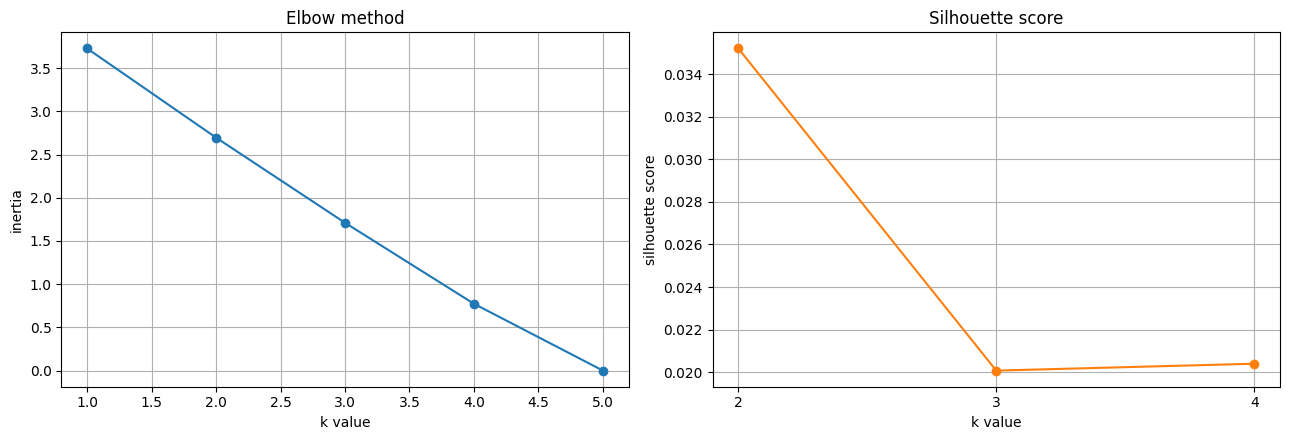

In [5]:
k = range(1, 6)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10, n_init=10)
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print([round(v, 4) for v in inertia])

# Silhouette untuk k = 2..4
sil = {}
for i in range(2, 5):
    lab = KMeans(n_clusters=i, random_state=10, n_init=10).fit(df_FE).labels_
    sil[i] = metrics.silhouette_score(df_FE, lab, metric='euclidean')
print({i: round(v, 4) for i, v in sil.items()})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(list(k), inertia, marker='o')
ax[0].set_xlabel('k value'); ax[0].set_ylabel('inertia'); ax[0].set_title('Elbow method'); ax[0].grid()
ax[1].plot(list(sil.keys()), list(sil.values()), marker='o', color='tab:orange')
ax[1].set_xlabel('k value'); ax[1].set_ylabel('silhouette score'); ax[1].set_title('Silhouette score')
ax[1].set_xticks(list(sil.keys())); ax[1].grid()
plt.tight_layout(); plt.show()

### 1.2 Model K-Means dengan k = 3

Pemilihan k dibahas di bagian analisis.

In [6]:
n_clusters = 3
kM = KMeans(n_clusters=n_clusters, random_state=10, n_init=10).fit(df_FE)
df['Kmeans_label'] = kM.labels_
print('Silhouette score :', round(metrics.silhouette_score(df_FE, kM.labels_, metric='euclidean'), 4))
df[['prepro', 'Kmeans_label']]

Silhouette score : 0.0201


,prepro,Kmeans_label
0,welcome retro website,1
1,retro things implemented retro tech like html ...,1
2,read built post blog building website fit,2
3,site available https modern browsers http retr...,1
4,live energy stats server since websites serve ...,0


In [7]:
# Kata dengan bobot TF-IDF rata-rata tertinggi di setiap cluster (pusat cluster)
terms = np.array(vectorizer.get_feature_names_out())

def top_terms(labels, n_top=5):
    for c in sorted(set(labels)):
        if c == -1:
            continue
        idx = np.where(np.array(labels) == c)[0]
        centroid = df_FE.iloc[idx].mean(axis=0).values
        top = terms[centroid.argsort()[::-1][:n_top]]
        print(f"Cluster {c} (Doc {', '.join(map(str, idx))}): {', '.join(top)}")

top_terms(kM.labels_)

Cluster 0 (Doc 4): websites, stats, since, one, serve
Cluster 1 (Doc 0, 1, 3): retro, welcome, browsers, website, tables
Cluster 2 (Doc 2): post, read, building, fit, built


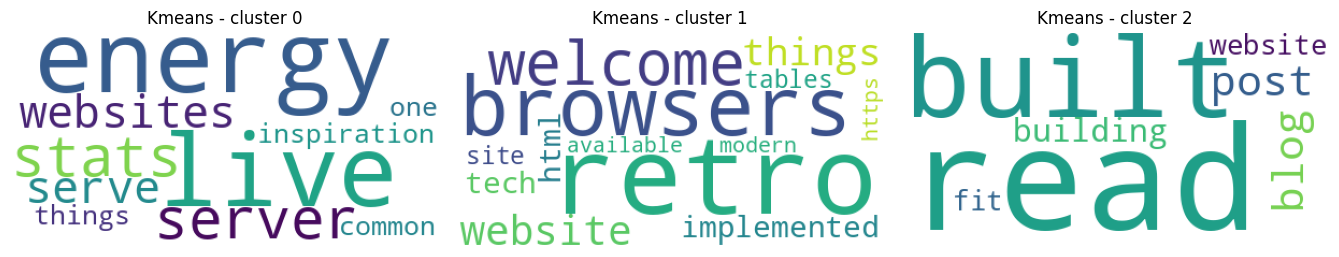

In [8]:
# Word cloud per cluster (seperti contoh dosen)
def show_wordclouds(labels, title):
    cl = [c for c in sorted(set(labels)) if c != -1]
    fig, axes = plt.subplots(1, len(cl), figsize=(4.5 * len(cl), 3.5))
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cl):
        text = ','.join(df.loc[np.array(labels) == c, 'prepro'].values)
        wc = WordCloud(background_color="white", max_words=5000, contour_width=3).generate(text)
        ax.imshow(wc.to_image()); ax.axis('off'); ax.set_title(f'{title} - cluster {c}')
    plt.tight_layout(); plt.show()

show_wordclouds(kM.labels_, 'Kmeans')

## 2. Hierarchical Clustering (Agglomerative)

Setiap dokumen dimulai sebagai cluster sendiri, lalu dua cluster terdekat digabung berulang-ulang sampai tersisa satu cluster. Hasilnya berupa **dendrogram**, dan jumlah cluster ditentukan dengan memotong dendrogram. Linkage yang dibandingkan: **ward** (jarak euclidean), serta **complete**, **average**, dan **single** (jarak cosine). *Cophenetic correlation* mengukur seberapa baik dendrogram mempertahankan jarak asli antar dokumen (makin dekat 1 makin baik).

Cophenetic correlation: {'ward (euclidean)': np.float64(0.785), 'complete (cosine)': np.float64(0.749), 'average (cosine)': np.float64(0.781), 'single (cosine)': np.float64(0.696)}


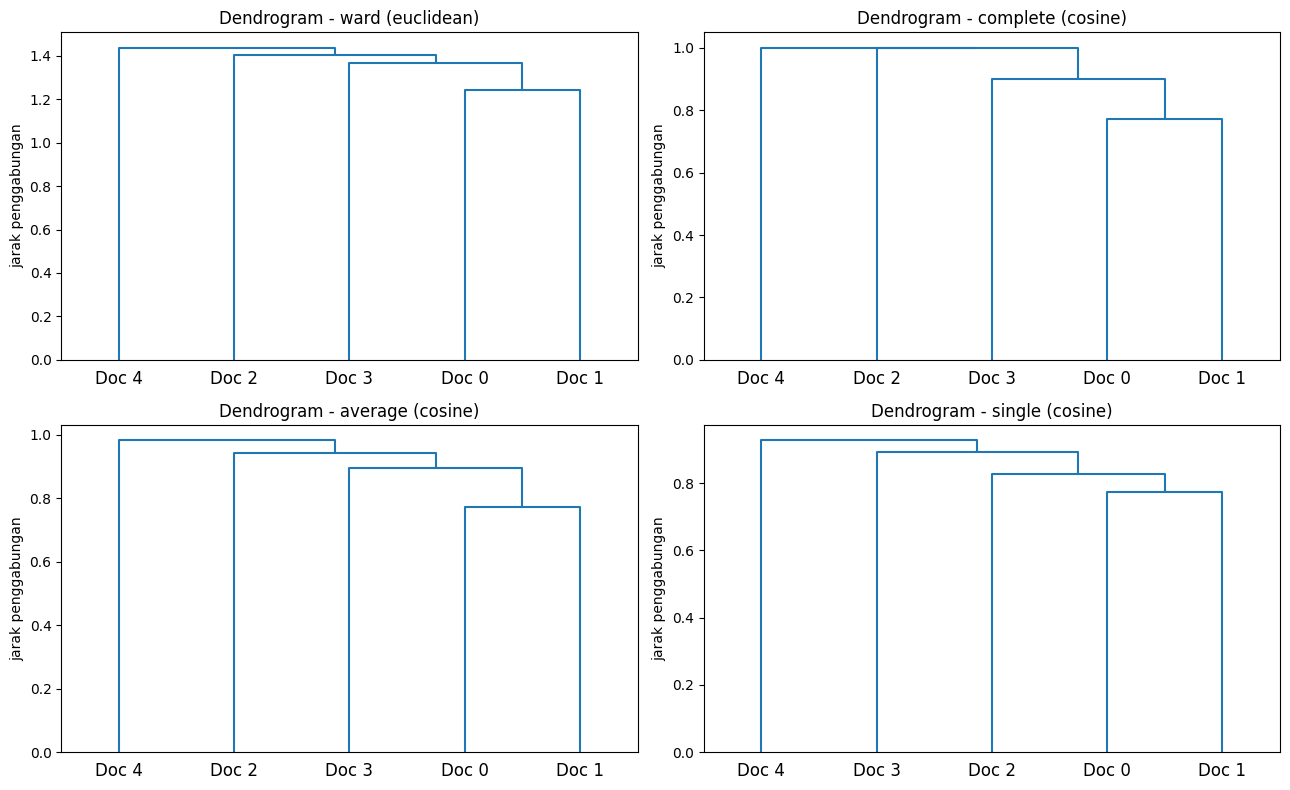

In [9]:
Xv = df_FE.values
linkages = {
    'ward (euclidean)'   : linkage(Xv, method='ward'),
    'complete (cosine)'  : linkage(Xv, method='complete', metric='cosine'),
    'average (cosine)'   : linkage(Xv, method='average',  metric='cosine'),
    'single (cosine)'    : linkage(Xv, method='single',   metric='cosine'),
}
orig_dist = {'ward (euclidean)': pdist(Xv, 'euclidean')}
for name in list(linkages)[1:]:
    orig_dist[name] = pdist(Xv, 'cosine')

coph = {name: round(cophenet(Z, orig_dist[name])[0], 3) for name, Z in linkages.items()}
print('Cophenetic correlation:', coph)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (name, Z) in zip(axes.ravel(), linkages.items()):
    dendrogram(Z, labels=labels_doc, ax=ax)
    ax.set_title(f'Dendrogram - {name}'); ax.set_ylabel('jarak penggabungan')
plt.tight_layout(); plt.show()

In [10]:
# Urutan penggabungan pada linkage ward
pd.DataFrame(linkages['ward (euclidean)'], columns=['cluster A', 'cluster B', 'jarak', 'jumlah dokumen']).round(3)

,cluster A,cluster B,jarak,jumlah dokumen
0,0.0,1.0,1.243,2.0
1,3.0,5.0,1.369,3.0
2,2.0,6.0,1.404,4.0
3,4.0,7.0,1.436,5.0


In [11]:
n_clusters = 3
agg_models = {
    'ward'    : AgglomerativeClustering(n_clusters=n_clusters, linkage='ward'),
    'complete': AgglomerativeClustering(n_clusters=n_clusters, linkage='complete', metric='cosine'),
    'average' : AgglomerativeClustering(n_clusters=n_clusters, linkage='average',  metric='cosine'),
    'single'  : AgglomerativeClustering(n_clusters=n_clusters, linkage='single',   metric='cosine'),
}
agg_labels = {name: m.fit_predict(df_FE) for name, m in agg_models.items()}

pd.DataFrame(agg_labels, index=labels_doc)

,ward,complete,average,single
Doc 0,0,0,0,0
Doc 1,0,0,0,0
Doc 2,2,2,2,0
Doc 3,0,0,0,2
Doc 4,1,1,1,1


In [12]:
for name, lab in agg_labels.items():
    print(f"Silhouette ({name}): {metrics.silhouette_score(df_FE, lab, metric='euclidean'):.4f}")
print()
print('Cluster ward:')
top_terms(agg_labels['ward'])

Silhouette (ward): 0.0201
Silhouette (complete): 0.0201
Silhouette (average): 0.0201
Silhouette (single): 0.0217

Cluster ward:
Cluster 0 (Doc 0, 1, 3): retro, welcome, browsers, website, tables
Cluster 1 (Doc 4): websites, stats, since, one, serve
Cluster 2 (Doc 2): post, read, building, fit, built


## 3. DBSCAN (Density-Based)

DBSCAN tidak membutuhkan jumlah cluster. Dokumen dikelompokkan jika berada dalam jarak **`eps`** dari paling sedikit **`min_samples`** dokumen (termasuk dirinya sendiri), dan dokumen yang tidak memenuhi syarat dilabeli **−1 (noise)**. Jarak yang dipakai adalah **cosine distance** (= 1 − cosine similarity pada TF-IDF), jadi `eps` berada pada rentang 0 sampai 1. `min_samples` = 2 karena korpusnya hanya 5 dokumen.

In [13]:
cos_dist = 1 - cosine_similarity(X)
print('Jarak cosine antar dokumen (TF-IDF):')
pd.DataFrame(cos_dist, index=labels_doc, columns=labels_doc).round(3)

Jarak cosine antar dokumen (TF-IDF):


,Doc 0,Doc 1,Doc 2,Doc 3,Doc 4
Doc 0,0.000,0.773,0.826,0.899,1.000
Doc 1,0.773,-0.000,1.000,0.893,0.927
Doc 2,0.826,1.000,0.000,1.000,1.000
Doc 3,0.899,0.893,1.000,0.000,1.000
Doc 4,1.000,0.927,1.000,1.000,0.000


In [14]:
rows = []
for eps in [0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.00]:
    lab = DBSCAN(eps=eps, min_samples=2, metric='cosine').fit(X).labels_
    rows.append({'eps': eps,
                 'label tiap dokumen': list(lab),
                 'jumlah cluster': len(set(lab)) - (1 if -1 in lab else 0),
                 'jumlah noise': int((lab == -1).sum())})
pd.DataFrame(rows).set_index('eps')

,label tiap dokumen,jumlah cluster,jumlah noise
eps,,,
0.70,"[-1, -1, -1, -1, -1]",0,5
0.75,"[-1, -1, -1, -1, -1]",0,5
0.80,"[0, 0, -1, -1, -1]",1,3
0.85,"[0, 0, 0, -1, -1]",1,2
0.90,"[0, 0, 0, 0, -1]",1,1
0.95,"[0, 0, 0, 0, 0]",1,0
1.00,"[0, 0, 0, 0, 0]",1,0


In [15]:
eps = 0.85
db = DBSCAN(eps=eps, min_samples=2, metric='cosine').fit(X)
df['DBSCAN_label'] = db.labels_
print(f'eps = {eps}, min_samples = 2')
df[['prepro', 'DBSCAN_label']]

eps = 0.85, min_samples = 2


,prepro,DBSCAN_label
0,welcome retro website,0
1,retro things implemented retro tech like html ...,0
2,read built post blog building website fit,0
3,site available https modern browsers http retr...,-1
4,live energy stats server since websites serve ...,-1


In [16]:
top_terms(db.labels_)

Cluster 0 (Doc 0, 1, 2): retro, website, welcome, read, post


## 4. Spectral Clustering (Graph-Based)

Dokumen dipandang sebagai graf: setiap dokumen adalah simpul dan **cosine similarity** (hasil Exercise 6) menjadi bobot sisi antar dokumen. Graf lalu dipotong menjadi sejumlah cluster berdasarkan vektor eigen dari matriks Laplacian.

In [17]:
affinity = cosine_similarity(X)
n_clusters = 3
sc = SpectralClustering(n_clusters=n_clusters, affinity='precomputed', random_state=10)
df['Spectral_label'] = sc.fit_predict(affinity)
print('Silhouette score :', round(metrics.silhouette_score(df_FE, df['Spectral_label'], metric='euclidean'), 4))
df[['prepro', 'Spectral_label']]

Silhouette score : 0.0242


,prepro,Spectral_label
0,welcome retro website,2
1,retro things implemented retro tech like html ...,0
2,read built post blog building website fit,2
3,site available https modern browsers http retr...,0
4,live energy stats server since websites serve ...,1


In [18]:
top_terms(df['Spectral_label'].values)

Cluster 0 (Doc 1, 3): retro, browsers, tables, implemented, html
Cluster 1 (Doc 4): websites, stats, since, one, serve
Cluster 2 (Doc 0, 2): website, welcome, retro, read, post


## 5. Perbandingan Semua Metode (fitur TF-IDF)

In [19]:
df['Agglo_ward_label']    = agg_labels['ward']
df['Agglo_average_label'] = agg_labels['average']

hasil = df[['Kmeans_label', 'Agglo_ward_label', 'Agglo_average_label',
            'DBSCAN_label', 'Spectral_label']].copy()
hasil.index = labels_doc
hasil

,Kmeans_label,Agglo_ward_label,Agglo_average_label,DBSCAN_label,Spectral_label
Doc 0,1,0,0,0,2
Doc 1,1,0,0,0,0
Doc 2,2,2,2,0,2
Doc 3,1,0,0,-1,0
Doc 4,0,1,1,-1,1


In [20]:
# Silhouette dan kesepakatan antar metode (Adjusted Rand Index: 1 = sama persis, 0 = setara acak)
def sil(lab):
    # noise (-1) pada DBSCAN dikeluarkan; silhouette hanya bisa dihitung jika ada 2 sampai n-1 cluster
    lab = np.array(lab); m = lab != -1
    l = lab[m]
    if 2 <= len(set(l)) <= len(l) - 1:
        return round(metrics.silhouette_score(df_FE.values[m], l, metric='euclidean'), 4)
    return np.nan

ringkasan = pd.DataFrame({
    'jumlah cluster': [len(set(hasil[c])) - (1 if -1 in set(hasil[c]) else 0) for c in hasil],
    'jumlah noise'  : [int((hasil[c] == -1).sum()) for c in hasil],
    'silhouette'    : [sil(hasil[c]) for c in hasil],
}, index=hasil.columns)
ringkasan

,jumlah cluster,jumlah noise,silhouette
Kmeans_label,3,0,0.0201
Agglo_ward_label,3,0,0.0201
Agglo_average_label,3,0,0.0201
DBSCAN_label,1,2,NaN
Spectral_label,3,0,0.0242


In [21]:
ari = pd.DataFrame([[metrics.adjusted_rand_score(hasil[a], hasil[b]) for b in hasil] for a in hasil],
                   index=hasil.columns, columns=hasil.columns)
ari.round(2)

,Kmeans_label,Agglo_ward_label,Agglo_average_label,DBSCAN_label,Spectral_label
Kmeans_label,1.00,1.00,1.00,-0.09,0.21
Agglo_ward_label,1.00,1.00,1.00,-0.09,0.21
Agglo_average_label,1.00,1.00,1.00,-0.09,0.21
DBSCAN_label,-0.09,-0.09,-0.09,1.00,0.09
Spectral_label,0.21,0.21,0.21,0.09,1.00


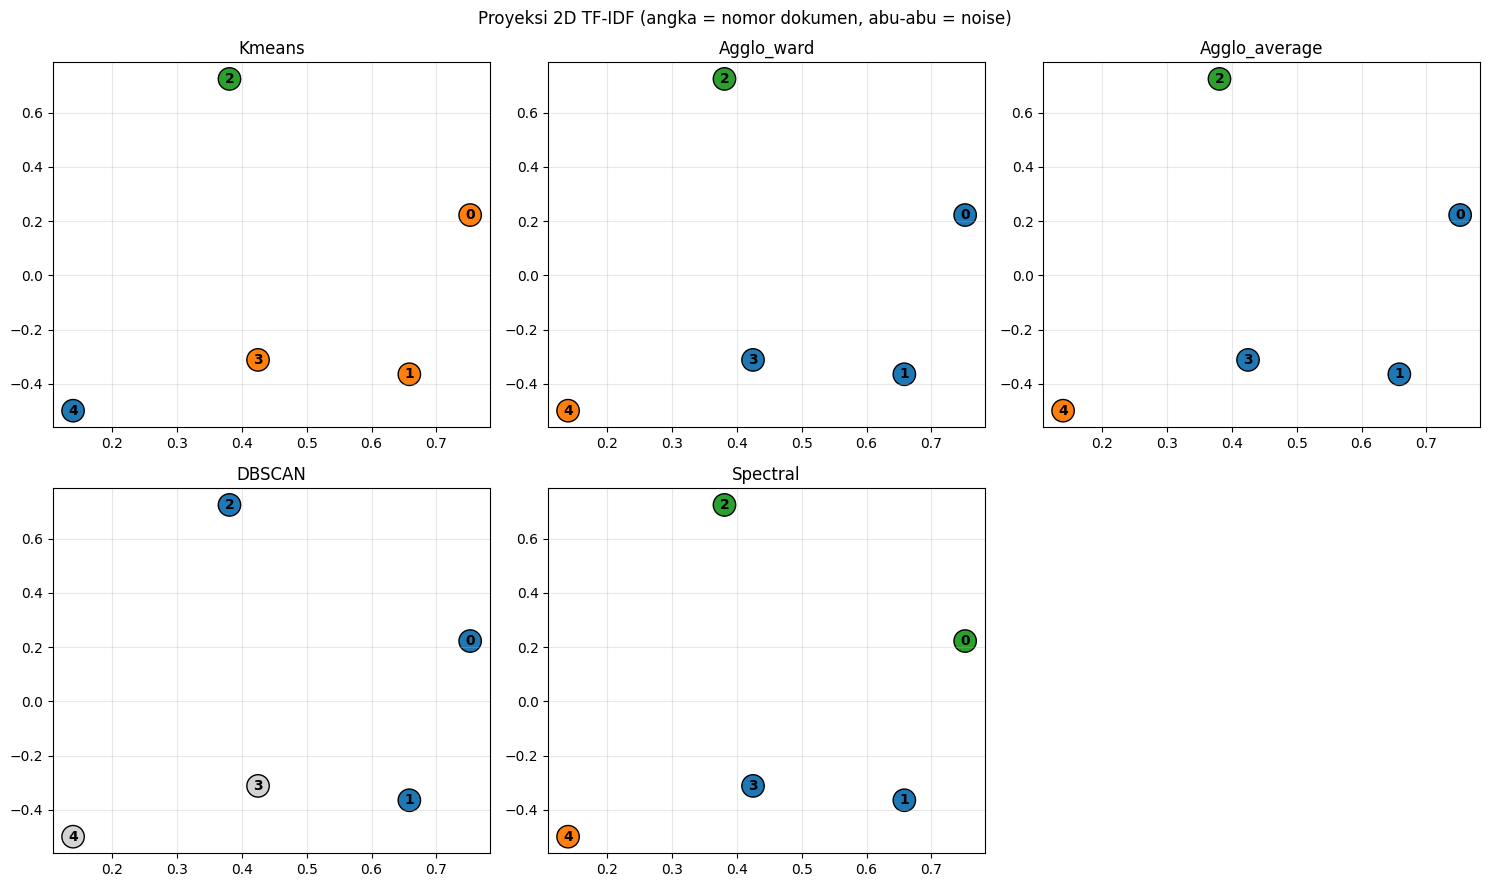

In [22]:
# Visualisasi 2D (TruncatedSVD pada TF-IDF)
xy = TruncatedSVD(n_components=2, random_state=10).fit_transform(X)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.ravel(), hasil.columns):
    lab = hasil[col].values
    ax.scatter(xy[:, 0], xy[:, 1], c=['lightgray' if l == -1 else plt.cm.tab10(l) for l in lab], s=260, edgecolor='k')
    for i, (x_, y_) in enumerate(xy):
        ax.annotate(f"{i}", (x_, y_), ha='center', va='center', fontsize=10, fontweight='bold')
    ax.set_title(col.replace('_label', '')); ax.grid(alpha=0.3)
axes.ravel()[-1].axis('off')
plt.suptitle('Proyeksi 2D TF-IDF (angka = nomor dokumen, abu-abu = noise)')
plt.tight_layout(); plt.show()

## 6. Perbandingan Representasi Fitur

K-Means dan Hierarchical (ward) diterapkan pada semua representasi dari Exercise 5 dengan jumlah cluster yang sama, untuk melihat apakah hasilnya bergantung pada fitur.

In [23]:
n_clusters = 3
fitur = {'BoW': X_bow, 'TF-IDF': df_FE.values, 'Binary (OHE)': X_bin, 'Word2Vec': X_w2v, 'FastText': X_ft}

lab_f, ringkas_f = {}, []
for name, F in fitur.items():
    km = KMeans(n_clusters=n_clusters, random_state=10, n_init=10).fit(F).labels_
    ag = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward').fit_predict(F)
    lab_f[f'KMeans - {name}'] = km
    lab_f[f'Ward - {name}'] = ag
    ringkas_f.append({'fitur': name,
                      'silhouette KMeans': round(metrics.silhouette_score(F, km), 3),
                      'silhouette Ward': round(metrics.silhouette_score(F, ag), 3)})

pd.DataFrame(lab_f, index=labels_doc)

,KMeans - BoW,Ward - BoW,KMeans - TF-IDF,Ward - TF-IDF,KMeans - Binary (OHE),Ward - Binary (OHE),KMeans - Word2Vec,Ward - Word2Vec,KMeans - FastText,Ward - FastText
Doc 0,1,0,1,0,1,0,1,1,1,0
Doc 1,1,0,1,0,1,0,0,0,1,0
Doc 2,1,0,2,2,2,2,0,0,2,2
Doc 3,0,2,1,0,1,0,2,2,0,1
Doc 4,2,1,0,1,0,1,0,0,0,1


In [24]:
pd.DataFrame(ringkas_f).set_index('fitur')

,silhouette KMeans,silhouette Ward
fitur,,
BoW,0.078,0.078
TF-IDF,0.020,0.020
Binary (OHE),0.064,0.064
Word2Vec,0.076,0.076
FastText,0.096,0.096


In [25]:
# Kesepakatan setiap representasi dengan hasil K-Means TF-IDF (ARI)
ref = lab_f['KMeans - TF-IDF']
pd.Series({k: round(metrics.adjusted_rand_score(ref, v), 2) for k, v in lab_f.items()},
          name='ARI terhadap KMeans - TF-IDF').to_frame()

,ARI terhadap KMeans - TF-IDF
KMeans - BoW,0.05
Ward - BoW,0.05
KMeans - TF-IDF,1.00
Ward - TF-IDF,1.00
KMeans - Binary (OHE),1.00
Ward - Binary (OHE),1.00
KMeans - Word2Vec,-0.43
Ward - Word2Vec,-0.43
KMeans - FastText,0.21
Ward - FastText,0.21


## Analisis Hasil

Korpus yang dipakai sangat kecil: **5 dokumen dan 31 fitur TF-IDF**. Pada TF-IDF, 5 dari 10 pasangan dokumen memiliki cosine similarity tepat 0 dan nilai tertinggi hanya 0,227 (lihat Exercise 6), sehingga dokumen-dokumennya hampir saling "tegak lurus" dan hampir tidak ada struktur cluster yang kuat. Hal ini memengaruhi semua hasil di bawah.

### 1. K-Means

**Menentukan k.** Inertia turun hampir linear: 3,727 (k=1), 2,696, 1,710, 0,773, dan 0 (k=5, setiap dokumen satu cluster). Selisih penurunannya (1,03; 0,99; 0,94; 0,77) hampir sama, jadi **tidak ada "siku" yang jelas**. Silhouette score pun sangat rendah di semua k: 0,035 (k=2), 0,020 (k=3), dan 0,020 (k=4). Nilai mendekati 0 berarti cluster saling tumpang tindih dan batasnya tidak tegas. Secara angka k=2 yang tertinggi, tetapi selisihnya terlalu kecil untuk dianggap bermakna, dan k=2 hanya memisahkan Doc 4 dari empat dokumen lainnya. Pada k=3, Doc 2 ikut terpisah, dan satu-satunya cluster berisi lebih dari satu dokumen punya tema yang bisa dijelaskan. Karena itu dipilih **k = 3** sebagai kompromi. Pada k=4, Doc 3 juga terpisah sehingga cluster tersisa hanya Doc 0 dan Doc 1.

**Hasil k = 3.** Cluster pertama berisi **Doc 0, 1, dan 3** dengan kata teratas `retro`, `welcome`, `browsers`, `website`, `tables`. Ketiganya sama-sama memuat kata `retro`, sehingga ini adalah cluster bertema "website retro". Doc 2 (kalimat tentang blog dan post) menjadi cluster sendiri, begitu juga Doc 4 (kalimat tentang energy stats dan server). Silhouette-nya 0,020. Cluster yang hanya berisi satu dokumen punya silhouette 0 menurut definisinya, dan word cloud-nya hanya menampilkan kata dari satu kalimat sehingga kurang informatif. Hanya word cloud cluster Doc 0, 1, 3 yang memperlihatkan pola (`retro` paling besar).

### 2. Hierarchical Clustering

Cophenetic correlation untuk keempat linkage cukup mirip: ward 0,785, average 0,781, complete 0,749, dan single 0,696. Ward dan average paling baik mempertahankan jarak asli, tetapi selisih keduanya kecil.

Urutan penggabungan pada ward: Doc 0 dan Doc 1 bergabung lebih dulu (jarak 1,243), lalu Doc 3 (1,369), lalu Doc 2 (1,404), dan **Doc 4 paling akhir** (1,436). Seluruh jarak penggabungan berada pada rentang sempit 1,24 sampai 1,44, artinya dokumen bergabung satu per satu seperti rantai tanpa celah yang jelas antar kelompok. Doc 4 bergabung terakhir, konsisten dengan temuan bahwa Doc 4 adalah dokumen yang paling terisolasi.

Jika dendrogram dipotong menjadi 3 cluster, **ward, complete, dan average menghasilkan pembagian yang sama persis dengan K-Means** (ARI = 1,00): {Doc 0, 1, 3}, {Doc 2}, {Doc 4}. Hanya **single linkage** yang berbeda: {Doc 0, 1, 2}, {Doc 3}, {Doc 4}. Single linkage memakai jarak minimum antar anggota cluster, dan Doc 2 punya jarak yang lebih dekat ke Doc 0 (0,826, lewat kata `website`) dibanding jarak Doc 3 ke Doc 0 atau Doc 1 (0,899 dan 0,893), sehingga Doc 2 digabung lebih dulu. Ini contoh efek *chaining* pada single linkage.

### 3. DBSCAN

Jarak cosine antar dokumen hanya berada pada rentang sempit, 0,773 sampai 1,0. Pasangan terdekat adalah Doc 0 – Doc 1 (0,773), diikuti Doc 0 – Doc 2 (0,826), Doc 1 – Doc 3 (0,893), Doc 0 – Doc 3 (0,899), dan Doc 1 – Doc 4 (0,927). Lima pasangan lain berjarak 1,0.

Hasil variasi `eps` (min_samples = 2): pada 0,70 dan 0,75 semua dokumen adalah noise; pada 0,80 terbentuk cluster {Doc 0, 1} dengan 3 noise; pada 0,85 cluster membesar menjadi {Doc 0, 1, 2} dengan Doc 3 dan 4 sebagai noise; pada 0,90 menjadi {Doc 0, 1, 2, 3} dengan hanya Doc 4 sebagai noise; dan pada 0,95 ke atas semua dokumen masuk satu cluster. Berapa pun `eps`, DBSCAN **tidak pernah menghasilkan lebih dari satu cluster**, karena jarak antar dokumen hampir seragam sehingga tidak ada perbedaan kepadatan yang bisa dipakai untuk memisahkan kelompok. Cluster hanya "tumbuh" ketika `eps` dinaikkan. Urutan dokumen yang bergabung (0 dan 1, lalu 2, lalu 3, lalu 4) sejalan dengan dendrogram, dan Doc 4 sekali lagi yang paling terakhir.

Pada `eps` = 0,85 yang dipilih, Doc 3 dianggap noise padahal K-Means memasukkannya ke cluster "retro". Penyebabnya, jarak Doc 3 ke tetangga terdekatnya (0,893) lebih besar daripada `eps`. Silhouette DBSCAN tidak bisa dihitung karena hanya ada satu cluster.

### 4. Spectral Clustering

Dengan k = 3, hasilnya {Doc 0, 2}, {Doc 1, 3}, dan {Doc 4}. Doc 0 punya kemiripan yang hampir sebanding dengan Doc 1 (0,227), Doc 2 (0,174), dan Doc 3 (0,101), sehingga ke mana Doc 0 dikelompokkan sangat bergantung pada cara metode memotong graf. Spectral memasangkan Doc 0 dengan Doc 2 (kata `website`) dan Doc 1 dengan Doc 3 (kata `retro`), sedangkan K-Means dan hierarchical menggabungkan Doc 0, 1, dan 3. Kedua pembagian sama-sama dapat dibenarkan oleh kata yang dipakai bersama, yang menunjukkan data ini memang ambigu. Silhouette spectral 0,024 adalah yang tertinggi di antara metode ber-k = 3, tetapi selisihnya dengan 0,020 terlalu kecil untuk disimpulkan sebagai lebih baik.

### 5. Perbandingan Semua Metode

K-Means, ward, dan average menghasilkan pembagian identik (ARI = 1,00 di antara ketiganya). Spectral cukup berbeda (ARI 0,21 terhadap K-Means), dan DBSCAN hampir tidak sepakat dengan metode lain (ARI −0,09), karena noise dihitung sebagai satu kelompok sendiri dan DBSCAN hanya membentuk satu cluster.

Walaupun pembagiannya berbeda, ada dua temuan yang konsisten. Pertama, **Doc 4 selalu terisolasi**: menjadi cluster sendiri di K-Means, hierarchical, dan spectral, serta menjadi noise di DBSCAN. Kedua, **Doc 0 dan Doc 1 dikelompokkan bersama pada empat dari lima hasil di tabel perbandingan** (hanya spectral yang memisahkannya). Silhouette semua metode berada pada 0,020 sampai 0,024, artinya kualitas cluster sama-sama rendah dan tidak ada metode yang jelas lebih baik berdasarkan angka ini.

### 6. Perbandingan Representasi Fitur

Pada k = 3, K-Means dan ward menghasilkan pembagian yang sama pada kelima representasi. Representasi **Binary (OHE)** menghasilkan pembagian yang identik dengan TF-IDF (ARI 1,00). **BoW** berbeda (ARI 0,05): Doc 0, 1, dan 2 dikelompokkan bersama dan Doc 3 menjadi cluster sendiri. Hal ini wajar karena BoW memakai hitungan mentah tanpa normalisasi panjang dokumen, sehingga kata yang berulang seperti `retro` (2 kali di Doc 1) dan `browsers` (2 kali di Doc 3) memengaruhi jarak euclidean. TF-IDF dinormalisasi per dokumen sehingga lebih tahan terhadap hal ini.

**Word2Vec** menghasilkan pembagian yang paling berbeda (ARI −0,43, lebih buruk daripada acak): {Doc 1, 2, 4}, {Doc 0}, dan {Doc 3}. Pengelompokan Doc 1, 2, dan 4 tidak punya kata bersama yang bisa menjelaskannya, sejalan dengan analisis Exercise 6 bahwa vektor Word2Vec dari korpus 37 token didominasi *noise*. **FastText** menghasilkan {Doc 0, 1}, {Doc 3, 4}, dan {Doc 2} (ARI 0,21), dan pengelompokan Doc 3 dengan Doc 4 juga tidak punya dasar kata bersama. Nilai silhouette BoW (0,078), Binary (0,064), Word2Vec (0,076), dan FastText (0,096) tampak lebih tinggi daripada TF-IDF (0,020), tetapi nilai ini dihitung di ruang fitur yang berbeda sehingga tidak bisa dibandingkan langsung, dan semuanya tetap rendah.

### Kesimpulan

Korpus lima kalimat ini tidak memiliki struktur cluster yang kuat: tidak ada elbow yang jelas dan silhouette score semua metode berada di sekitar 0,02. Dengan pembagian k = 3, K-Means dan hierarchical (ward, average, complete) menemukan hasil yang sama: satu cluster bertema "website retro" berisi Doc 0, 1, dan 3, serta Doc 2 dan Doc 4 yang masing-masing berdiri sendiri. Semua metode juga sepakat bahwa Doc 4 adalah dokumen yang paling terisolasi.

Perbedaan antar metode mencerminkan karakter masing-masing. Single linkage dan DBSCAN cenderung membentuk rantai berdasarkan pasangan terdekat. DBSCAN sulit dipakai karena jarak antar dokumen hampir seragam. Spectral clustering mengikuti struktur graf dan memberikan pembagian lain yang sama-sama dapat dibenarkan. Untuk korpus sekecil ini, **hierarchical clustering dengan dendrogram** paling informatif karena memperlihatkan urutan penggabungan dan dokumen mana yang paling terisolasi, sedangkan K-Means dengan TF-IDF memberi hasil yang sama dan mudah ditafsirkan lewat kata teratas tiap cluster. Representasi Word2Vec dan FastText sebaiknya tidak dipakai untuk clustering pada korpus sekecil ini.

**Keterbatasan:** dengan hanya 5 dokumen, hasil clustering sangat sensitif terhadap satu kata yang dipakai bersama dan nilai silhouette hampir tidak informatif. Untuk hasil yang bermakna, clustering perlu dijalankan pada korpus yang jauh lebih besar (misalnya dataset tweet pada contoh dosen). Kode di notebook ini bergantung pada `df['prepro']` sehingga dapat dipakai ulang dengan mengganti sumber datanya, tetapi teks analisis di atas perlu ditulis ulang sesuai hasil data baru.